# Bài 6. Tối ưu hàm đếm xung đột bằng Numba (n-Queens)
**Yêu cầu:** đối chiếu `conflicts_naive()` / `conflicts()` / `conflicts_jit()`, giải thích đếm theo hàng/chéo + `C(k,2)`, đo thời gian nhiều cỡ bàn cờ (warm-up JIT trước khi đo), vẽ đồ thị `O(n²)` vs `O(n)`, phân biệt độ phức tạp thuật toán vs lợi ích JIT.

In [1]:
import math, timeit
import numpy as np
import matplotlib.pyplot as plt


## 1. Naive $O(n^2)$ — so từng cặp
Mỗi hàng quét $n$ ô; mỗi hậu quét chéo sang phải → 2 vòng lặp lồng nhau.

In [2]:
def conflicts_naive(board):
    """Naive O(n^2): nested loops."""
    board = np.array(board)
    n = len(board)
    val = 0
    for i in range(n):
        val += math.comb(np.sum(board == i), 2)
    for j in range(n):
        q_up, q_down = board[j], board[j]
        for jj in range(j+1, n):
            q_up -= 1; q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
    return val


## 2. $O(n)$ — đếm theo hàng/chéo + $C(k,2)$
Duyệt $n$ hậu 1 lần, đếm số hậu mỗi hàng ($n$), mỗi chéo ($2n$ mỗi loại). Nhóm có $k$ hậu → $C(k,2)=k(k-1)/2$ cặp xung đột, không cần so từng cặp. VD $k=3$ → 3 cặp tính $O(1)$.

In [3]:
def comb2(n):
    return n*(n-1)//2  # = C(n,2)

def conflicts(board):
    """O(n): count rows/diagonals then C(k,2)."""
    n = len(board)
    horizontal_cnt = [0]*n
    diagonal1_cnt = [0]*2*n
    diagonal2_cnt = [0]*2*n
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))


## 3. $O(n)$ + JIT — cùng thuật toán, biên dịch machine code

In [4]:
try:
    from numba import njit
    @njit()
    def comb2_jit(n):
        return n*(n-1)//2
    @njit()
    def conflicts_jit(board):
        n = len(board)
        cnt = [0]*(5*n)
        for i in range(n):
            cnt[board[i]] += 1
            cnt[(n) + (i + board[i])] += 1
            cnt[(3*n) + (i - board[i] + n)] += 1
        s = 0
        for x in cnt:
            s += comb2_jit(x)
        return s
    print('numba JIT san sang')
except Exception as e:
    print(f'Chua co numba ({e}); dung fallback de van chay duoc O(n^2) vs O(n). Tren Colab co numba se chay JIT that.')
    def comb2_jit(n):
        return n*(n-1)//2
    def conflicts_jit(board):
        return conflicts(board)


Chua co numba (No module named 'numba'); dung fallback de van chay duoc O(n^2) vs O(n). Tren Colab co numba se chay JIT that.


In [5]:
np.random.seed(1234)
def random_board(n):
    return np.random.randint(0, n, size=n)

# Kiem tra dung dan: 3 ham phai bang nhau
for b in [[0,0,0,0],[0,1,2,3],[1,3,0,2],[2,0,3,1]]:
    print(b, conflicts_naive(b), conflicts(b), conflicts_jit(np.array(b)))


[0, 0, 0, 0] 6 6 6
[0, 1, 2, 3] 6 6 6
[1, 3, 0, 2] 0 0 0
[2, 0, 3, 1] 0 0 0


## 4. Đo thời gian (nhớ warm-up JIT trước khi đo)

In [6]:
import timeit
# QUAN TRONG: goi 1 lan truoc khi do de loai thoi gian bien dich JIT
conflicts_jit(random_board(4))

reps = 20
x, naive_times, linear_times, jit_times = [], [], [], []
for i in [8] + list(range(50, 500, 50)):
    boards = [random_board(i) for _ in range(reps)]
    naive = timeit.timeit(lambda: [conflicts_naive(b) for b in boards], number=1)
    linear = timeit.timeit(lambda: [conflicts(b) for b in boards], number=1)
    jit = timeit.timeit(lambda: [conflicts_jit(b) for b in boards], number=1)
    x.append(i); naive_times.append(naive); linear_times.append(linear); jit_times.append(jit)
naive_times = np.array(naive_times)/reps*1e6
linear_times = np.array(linear_times)/reps*1e6
jit_times = np.array(jit_times)/reps*1e6
print("Times for 8x8 board in microseconds")
print(f"naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}")
for n_, a, c, j in zip(x, naive_times, linear_times, jit_times):
    print(f"n={n_:3d}: naive {a:9.1f} | linear {c:7.1f} | jit {j:7.1f} us/board | x{a/c:.1f}/{a/j:.1f}")


Times for 8x8 board in microseconds
naive: 28.700000257231295, linear: 5.729999975301325, jit: 5.575000250246376
n=  8: naive      28.7 | linear     5.7 | jit     5.6 us/board | x5.0/5.1
n= 50: naive     358.9 | linear    32.3 | jit    30.5 us/board | x11.1/11.7
n=100: naive    1487.0 | linear    60.3 | jit    57.9 us/board | x24.7/25.7
n=150: naive    2216.1 | linear    81.7 | jit    80.5 us/board | x27.1/27.5
n=200: naive    3834.3 | linear   150.8 | jit   112.3 us/board | x25.4/34.1
n=250: naive    6103.9 | linear   153.0 | jit   182.0 us/board | x39.9/33.5
n=300: naive   10053.9 | linear   353.8 | jit   278.6 us/board | x28.4/36.1
n=350: naive   11877.4 | linear   200.5 | jit   208.7 us/board | x59.3/56.9
n=400: naive   14695.4 | linear   227.7 | jit   240.8 us/board | x64.6/61.0
n=450: naive   18530.7 | linear   264.3 | jit   258.4 us/board | x70.1/71.7


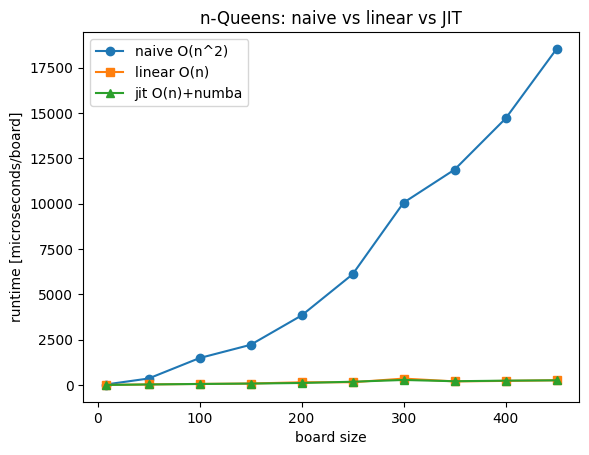

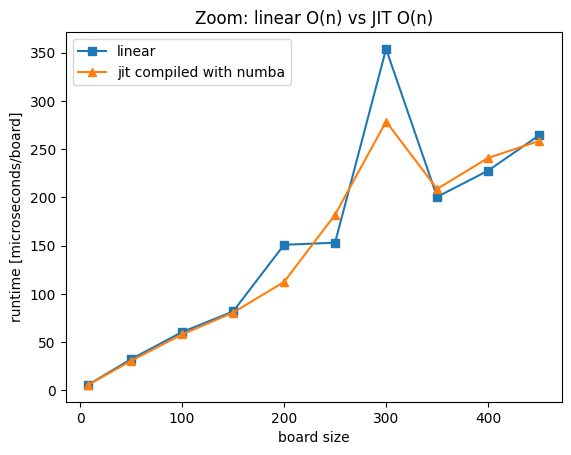

In [7]:
plt.plot(x, naive_times, marker="o")
plt.plot(x, linear_times, marker="s")
plt.plot(x, jit_times, marker="^")
plt.xlabel("board size"); plt.ylabel("runtime [microseconds/board]")
plt.legend(["naive O(n^2)", "linear O(n)", "jit O(n)+numba"])
plt.title("n-Queens: naive vs linear vs JIT")
plt.show()

plt.plot(x, linear_times, marker="s")
plt.plot(x, jit_times, marker="^")
plt.xlabel("board size"); plt.ylabel("runtime [microseconds/board]")
plt.legend(["linear", "jit compiled with numba"])
plt.title("Zoom: linear O(n) vs JIT O(n)")
plt.show()


**Nhận xét:** đường `naive` parabol $O(n^2)$, 2 đường kia tuyến tính $O(n)$. Khoảng cách naive–linear là do **độ phức tạp thuật toán** (đếm + $C(k,2)$), khoảng cách linear–jit là do **biên dịch JIT** (cùng $O(n)$ nhưng hằng số nhỏ hơn nhờ machine code).